# Problem Sheet 3 — Question 4

A measurement of four parameters gives

| | value |
|---|---|
| $x^+$ | $-9.3 \pm 8.2$ |
| $y^+$ | $-1.3 \pm 8.4$ |
| $x^-$ | $\phantom{-}5.7 \pm 8.2$ |
| $y^-$ | $\phantom{-}6.5 \pm 8.3$ |

with a known correlation matrix. The physics parameters $(\gamma, r, \delta)$ are related to these by

$$x^\pm = r\cos(\delta \pm \gamma), \qquad y^\pm = r\sin(\delta \pm \gamma).$$

* **(a)** Use the ML method to estimate the values, uncertainties and correlations of $(\gamma, r, \delta)$.
* **(b)** Make a profile likelihood scan for $r$. Any issues? Estimate the uncertainty on $r$, and the 95% interval.
* **(c)** Compute (or explain how to compute) the coverage of the interval on $\gamma$.
* **(d)** Explain how you could set an upper limit on $r$.

## Setup
Install `iminuit` if you don't have it (needed on Google Colab).

In [1]:
%pip install -q iminuit

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from iminuit import Minuit

deg = 180 / np.pi   # radians -> degrees

## The measurements

The covariance matrix is built from the uncertainties and correlations: $V_{ij} = \rho_{ij}\,\sigma_i\,\sigma_j$. Order: $x^+, y^+, x^-, y^-$.

In [3]:
obs = np.array([-9.3, -1.3, 5.7, 6.5])
err = np.array([8.2, 8.4, 8.2, 8.3])

corr = np.array([
    [ 1.00, -0.10, -0.05,  0.10],
    [-0.10,  1.00,  0.10, -0.05],
    [-0.05,  0.10,  1.00,  0.10],
    [ 0.10, -0.05,  0.10,  1.00],
])

cov = corr * np.outer(err, err)
cov_inv = np.linalg.inv(cov)

## The likelihood

For a multivariate normal distribution,

$$-2\ln L = (\mathbf{x}_\text{obs} - \mathbf{x}_\text{model})^T\, V^{-1}\, (\mathbf{x}_\text{obs} - \mathbf{x}_\text{model}) + \text{const},$$

so maximising $L$ is the same as minimising this $\chi^2$. We minimise $-\ln L = \tfrac{1}{2}\chi^2$.

`make_nll(data)` builds the negative log-likelihood for any set of four measurements. We need this later in part (c), where we fit lots of simulated datasets.

In [4]:
def model(gamma, r, delta):
    """Predicted (x+, y+, x-, y-) for given parameters (angles in radians)."""
    return np.array([
        r * np.cos(delta + gamma),
        r * np.sin(delta + gamma),
        r * np.cos(delta - gamma),
        r * np.sin(delta - gamma),
    ])


def make_nll(data):
    """Return the negative log-likelihood function (= 0.5 * chi^2) for a dataset."""
    def nll(gamma, r, delta):
        d = data - model(gamma, r, delta)
        if not np.all(np.isfinite(d)):       # guard against the minimiser wandering off
            return 1e10
        return 0.5 * d @ cov_inv @ d
    return nll

## A fitting function

The sines and cosines give the likelihood several separate minima, so we start the minimiser from a grid of starting points and keep the best result. $r$ is a magnitude, so it is limited to $r \ge 0$.

`errordef = 0.5` tells Minuit we are minimising $-\ln L$ (rather than $\chi^2$), so the $1\sigma$ uncertainties are where $-\ln L$ rises by 0.5.

The `fix` option lets us hold a parameter at a chosen value and minimise over the others. That is exactly what a **profile likelihood** needs in parts (b) and (c).

In [5]:
def fit(data, fix=None, n_gamma=4, n_delta=6):
    """Fit (gamma, r, delta) to data. Returns the best Minuit object.

    fix: optional dict, e.g. {"r": 5.0}, of parameters to hold fixed.
    """
    nll = make_nll(data)
    fix = fix or {}
    g_starts = [fix["gamma"]] if "gamma" in fix else np.linspace(0, np.pi, n_gamma, endpoint=False)
    d_starts = np.linspace(-np.pi, np.pi, n_delta, endpoint=False)
    r_start = fix.get("r", max(np.hypot(data[0], data[1]), 1.0))

    best = None
    for g0 in g_starts:
        for d0 in d_starts:
            m = Minuit(nll, gamma=g0, r=r_start, delta=d0)
            m.errordef = Minuit.LIKELIHOOD   # 0.5
            m.limits["r"] = (0, None)
            for name in fix:
                m.fixed[name] = True
            m.migrad()
            if not np.isfinite(m.fval):      # skip any fit that went wrong
                continue
            if best is None or m.fval < best.fval:
                best = m
    return best


def tidy_angles(gamma, delta):
    """(gamma, delta) and (gamma + pi, delta + pi) give identical predictions.
    Put gamma in [0, pi) and delta in (-pi, pi]."""
    if gamma % (2 * np.pi) >= np.pi:
        gamma, delta = gamma - np.pi, delta - np.pi
    return gamma % np.pi, (delta + np.pi) % (2 * np.pi) - np.pi

---
# Part (a): Maximum likelihood fit

After MIGRAD finds the minimum, HESSE computes the uncertainties and correlations from the curvature (second derivatives) of $-\ln L$ there.

In [6]:
m = fit(obs, n_gamma=7, n_delta=9)
m.hesse()

gamma_hat, delta_hat = tidy_angles(m.values["gamma"], m.values["delta"])
r_hat = m.values["r"]
nll_min = m.fval

print(f"gamma = {gamma_hat * deg:6.1f} ± {m.errors['gamma'] * deg:4.1f} degrees")
print(f"r     = {r_hat:6.2f} ± {m.errors['r']:4.2f}")
print(f"delta = {delta_hat * deg:6.1f} ± {m.errors['delta'] * deg:4.1f} degrees")
print(f"\nchi^2 at minimum = {2 * nll_min:.3f}  (4 observables - 3 parameters = 1 dof)")

gamma =   69.6 ± 34.2 degrees
r     =   9.04 ± 5.76
delta =  118.5 ± 38.7 degrees

chi^2 at minimum = 0.004  (4 observables - 3 parameters = 1 dof)


### Correlation matrix

In [7]:
names = ["gamma", "r", "delta"]
corr_fit = np.array(m.covariance.correlation())
print("        " + "".join(f"{n:>9}" for n in names))
for n, row in zip(names, corr_fit):
    print(f"{n:<8}" + "".join(f"{v:9.3f}" for v in row))

            gamma        r    delta
gamma       1.000   -0.009    0.048
r          -0.009    1.000   -0.101
delta       0.048   -0.101    1.000


### Check: does the fitted model reproduce the measurements?

In [8]:
pred = model(gamma_hat, r_hat, delta_hat)
for name, o, p in zip(["x+", "y+", "x-", "y-"], obs, pred):
    print(f"{name}: measured {o:5.1f}   fitted {p:6.2f}")

x+: measured  -9.3   fitted  -8.95
y+: measured  -1.3   fitted  -1.27
x-: measured   5.7   fitted   5.94
y-: measured   6.5   fitted   6.82


**Comments on (a)**

* $\chi^2 \approx 0$ at the minimum: with 4 measurements and 3 parameters there is only 1 degree of freedom, so the model can match the data very closely.
* The correlations between $\gamma$, $r$ and $\delta$ are small.
* HESSE assumes the likelihood is a parabola (a Gaussian) near the minimum. Part (b) checks this for $r$, and part (c) shows where it breaks down for $\gamma$.

---
# Part (b): Profile likelihood scan for $r$

For each value of $r$ on a grid, fix $r$ and minimise $-\ln L$ over the other parameters ($\gamma$ and $\delta$, called **nuisance parameters** here). Then plot

$$\Delta\chi^2(r) = -2\ln\frac{L(r,\ \hat{\hat\gamma},\ \hat{\hat\delta})}{L(\hat r, \hat\gamma, \hat\delta)}$$

where the double hat means "best value with $r$ held fixed".

By **Wilks' theorem**, $\Delta\chi^2$ is approximately a $\chi^2$ distribution with 1 degree of freedom, so:

* $\Delta\chi^2 = 1$ gives the $68.3\%$ ($1\sigma$) interval
* $\Delta\chi^2 = 3.84$ gives the $95\%$ interval

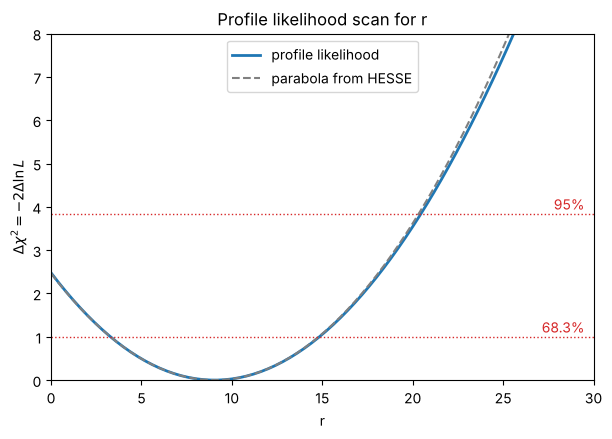

In [9]:
r_scan = np.linspace(0, 30, 151)
dchi2_r = np.array([2 * (fit(obs, fix={"r": r}).fval - nll_min) for r in r_scan])

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(r_scan, dchi2_r, color="C0", lw=2, label="profile likelihood")

# Parabola that HESSE assumes, for comparison
ax.plot(r_scan, ((r_scan - r_hat) / m.errors["r"]) ** 2, "--", color="grey",
        label="parabola from HESSE")

for level, text in [(1, "68.3%"), (3.84, "95%")]:
    ax.axhline(level, color="C3", lw=1, ls=":")
    ax.text(29.5, level + 0.1, text, color="C3", ha="right")

ax.set_xlabel("r")
ax.set_ylabel(r"$\Delta\chi^2 = -2\Delta\ln L$")
ax.set_ylim(0, 8)
ax.set_xlim(0, 30)
ax.legend(loc="upper center")
ax.set_title("Profile likelihood scan for r")
plt.show()

Now read off where the curve crosses each level (using linear interpolation between scan points).

In [10]:
def crossings(x, y, level, x_best):
    """Where y crosses `level` either side of x_best. Returns (low, high);
    None means the curve never rises above `level` on that side."""
    left, right = x <= x_best, x >= x_best
    xl, yl = x[left][::-1], y[left][::-1]     # moving left from the minimum
    xr, yr = x[right], y[right]
    low = np.interp(level, yl, xl) if yl.max() > level else None
    high = np.interp(level, yr, xr) if yr.max() > level else None
    return low, high


for level, text in [(1, "68.3%"), (3.84, "95%")]:
    lo, hi = crossings(r_scan, dchi2_r, level, r_hat)
    lo_txt = f"{lo:5.2f}" if lo is not None else " 0 (hits r = 0 boundary)"
    print(f"{text:>6} interval: r from {lo_txt} to {hi:5.2f}")

lo1, hi1 = crossings(r_scan, dchi2_r, 1, r_hat)
print(f"\n=> r = {r_hat:.1f} +{hi1 - r_hat:.1f} -{r_hat - lo1:.1f}")
print(f"Delta chi^2 at r = 0: {dchi2_r[0]:.2f}  (only {np.sqrt(dchi2_r[0]):.1f} sigma from zero)")

 68.3% interval: r from  3.29 to 14.84
   95% interval: r from  0 (hits r = 0 boundary) to 20.45

=> r = 9.0 +5.8 -5.8
Delta chi^2 at r = 0: 2.48  (only 1.6 sigma from zero)


**Comments on (b): what are the issues?**

1. **The physical boundary at $r = 0$.** This is the main issue. $r$ can't be negative, and $\Delta\chi^2(0) \approx 2.5 < 3.84$, so the 95% interval runs into the boundary. The parabola would carry on into negative $r$, which is unphysical. So the best we can quote at 95% is $0 \le r < 20.5$, and Wilks' theorem isn't reliable close to a boundary. Since $r$ is only $\approx 1.6\sigma$ from zero, an upper limit is arguably more useful (part (d)).
2. **$\gamma$ and $\delta$ become undefined at $r = 0$.** When $r = 0$ every prediction is zero, whatever $\gamma$ and $\delta$ are. So the likelihood is completely flat in those directions. When $r$ is small the angles are poorly determined, and the likelihood in $\gamma$ is far from Gaussian. This is where the real trouble shows up (part (c)).
3. **Multiple minima.** The trig functions mean there can be more than one local minimum. Every point of the scan has to be minimised from several starting points, which is why `fit` uses a grid of starts.
4. **The $r$ profile itself is close to a parabola**, so here the $1\sigma$ uncertainty from the scan ($r = 9.0^{+5.8}_{-5.8}$) agrees with HESSE. That isn't guaranteed: always check with a scan rather than trusting HESSE.

---
# Part (c): Coverage of the interval on $\gamma$

**Coverage** is the fraction of repeated experiments in which the quoted interval contains the true value. A "68.3% interval" should contain the truth 68.3% of the time. If it does so less often it **under-covers** (it's too narrow); if more often it **over-covers** (it's too conservative).

You can't check this with one dataset, so we use **pseudo-experiments (toys)**:

1. Pick "true" parameter values. A common choice is the best-fit values from the data.
2. Generate a fake set of $(x^\pm, y^\pm)$ from the multivariate normal distribution with those true means and the same covariance matrix.
3. Fit the fake dataset and work out the profile likelihood interval on $\gamma$.
4. Record whether the interval contains the true $\gamma$.
5. Repeat many times. The coverage is the fraction of successes.

**Shortcut:** the interval at level $\Delta\chi^2 = 1$ contains $\gamma_\text{true}$ exactly when

$$\Delta\chi^2(\gamma_\text{true}) = 2\left[\,{-\ln L}(\gamma_\text{true}) - (-\ln L_\text{min})\,\right] < 1.$$

So each toy needs just **two fits**: one with everything free, and one with $\gamma$ fixed at its true value. There's no need to scan the whole curve.

In [11]:
def coverage(gamma_true, r_true, delta_true, n_toys=1000, seed=1):
    """Fraction of toys whose 68.3% and 95% profile-likelihood intervals contain gamma_true."""
    rng = np.random.default_rng(seed)
    truth = model(gamma_true, r_true, delta_true)
    q = np.empty(n_toys)
    for i in range(n_toys):
        toy = rng.multivariate_normal(truth, cov)
        free = fit(toy)
        fixed = fit(toy, fix={"gamma": gamma_true})
        q[i] = 2 * (fixed.fval - free.fval)     # Delta chi^2 at the true gamma
    return np.mean(q < 1), np.mean(q < 3.84)


n_toys = 2000
cov68, cov95 = coverage(gamma_hat, r_hat, delta_hat, n_toys=n_toys)
err68 = np.sqrt(cov68 * (1 - cov68) / n_toys)      # binomial uncertainty
err95 = np.sqrt(cov95 * (1 - cov95) / n_toys)
print(f"True values: gamma = {gamma_hat*deg:.1f} deg, r = {r_hat:.2f}, delta = {delta_hat*deg:.1f} deg")
print(f"Coverage of '68.3%' interval: {cov68:.3f} ± {err68:.3f}")
print(f"Coverage of '95%'   interval: {cov95:.3f} ± {err95:.3f}")

True values: gamma = 69.6 deg, r = 9.04, delta = 118.5 deg
Coverage of '68.3%' interval: 0.574 ± 0.011
Coverage of '95%'   interval: 0.907 ± 0.006


The coverage is **below** the nominal values: the intervals on $\gamma$ are too narrow. This is because $r/\sigma \approx 1$ here. When $r$ is small, $\gamma$ is poorly determined and the likelihood isn't Gaussian, so Wilks' theorem doesn't hold.

The coverage depends on the true parameter values. Repeating the study for different true values of $r$ shows that it gets close to nominal once $r$ is large compared with the measurement uncertainty ($\approx 8$):

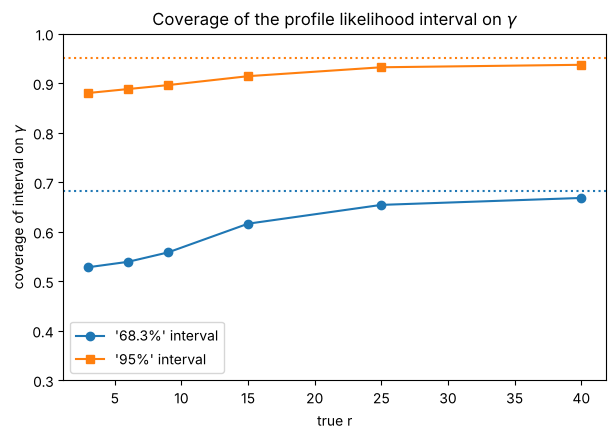

r =  3.0:  68.3% -> 0.528   95% -> 0.880
r =  6.0:  68.3% -> 0.539   95% -> 0.888
r =  9.0:  68.3% -> 0.558   95% -> 0.896
r = 15.0:  68.3% -> 0.616   95% -> 0.914
r = 25.0:  68.3% -> 0.654   95% -> 0.932
r = 40.0:  68.3% -> 0.668   95% -> 0.937


In [12]:
r_values = [3, 6, 9, 15, 25, 40]
results = [coverage(gamma_hat, r, delta_hat, n_toys=1000) for r in r_values]
c68, c95 = np.array(results).T

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(r_values, c68, "o-", label="'68.3%' interval")
ax.plot(r_values, c95, "s-", label="'95%' interval")
ax.axhline(0.683, color="C0", ls=":")
ax.axhline(0.95, color="C1", ls=":")
ax.set_xlabel("true r")
ax.set_ylabel(r"coverage of interval on $\gamma$")
ax.set_ylim(0.3, 1.0)
ax.legend()
ax.set_title(r"Coverage of the profile likelihood interval on $\gamma$")
plt.show()

for r, a, b in zip(r_values, c68, c95):
    print(f"r = {r:4.1f}:  68.3% -> {a:.3f}   95% -> {b:.3f}")

**Comments on (c)**

* Coverage has to be checked with **toys**, because it's a property of the method over many repeated experiments, not of one dataset.
* It depends on the true parameter values, especially $r$. Strictly, you'd check a range of plausible true values (including the nuisance parameter $\delta$), not just the best fit.
* At the measured $r$, the simple $\Delta\chi^2$ intervals **under-cover**. To get correct coverage you could use a **Neyman construction** / **Feldman–Cousins** method: use toys to find the $\Delta\chi^2$ threshold that really contains 68.3% (or 95%) of experiments, rather than assuming 1 (or 3.84) from Wilks' theorem.

---
# Part (d): Setting an upper limit on $r$

Part (b) showed that the 95% interval on $r$ hits the boundary at $r = 0$. When a parameter is not clearly different from zero, it makes more sense to quote an **upper limit**: "$r < r_\text{UL}$ at 95% confidence level".

**Method 1: one-sided profile likelihood (quick, approximate).** Only values *above* $\hat r$ are excluded, so the test is one-sided. For a one-sided 95% limit, put the 5% all in one tail. That means using $\Delta\chi^2 = 2.71$ (= $1.645^2$) instead of 3.84:

In [13]:
_, r_ul = crossings(r_scan, dchi2_r, 2.71, r_hat)
print(f"Approximate 95% CL upper limit (Delta chi^2 = 2.71): r < {r_ul:.1f}")

Approximate 95% CL upper limit (Delta chi^2 = 2.71): r < 18.6


**Method 2: toys / Neyman construction (correct coverage).** Because $r$ sits near a physical boundary and the likelihood isn't Gaussian, the $\Delta\chi^2 = 2.71$ rule may not give true 95% coverage. A more reliable way:

1. For each trial value $r_\text{test}$, generate many toys with $r = r_\text{test}$ (and the nuisance parameters $\gamma$, $\delta$ set to their profiled best values for that $r_\text{test}$).
2. For each toy, compute the test statistic $q(r_\text{test}) = \Delta\chi^2(r_\text{test})$, setting $q = 0$ if the toy's best fit $\hat r > r_\text{test}$ (a one-sided test: an upward fluctuation shouldn't count against $r_\text{test}$).
3. Find the p-value: the fraction of toys with $q$ larger than the $q$ seen in the real data.
4. The upper limit is the value of $r_\text{test}$ where the p-value drops to 5%.

Other approaches you might see:

* **Feldman–Cousins (unified approach):** uses a likelihood-ratio ordering that automatically switches between a two-sided interval and an upper limit, and handles the $r \ge 0$ boundary properly.
* **CL$_s$ method:** common in particle physics. It protects against excluding values you have no sensitivity to.
* **Bayesian:** put a prior on $r$ (e.g. flat for $r \ge 0$), integrate out $\gamma$ and $\delta$, and find the value below which 95% of the posterior lies. The answer depends on the choice of prior.

---
# Summary

| Part | Result |
|---|---|
| (a) | $\gamma \approx 70^\circ \pm 34^\circ$, $r \approx 9.0 \pm 5.8$, $\delta \approx 119^\circ \pm 39^\circ$, small correlations |
| (b) | $r = 9.0^{+5.8}_{-5.8}$ at 68.3%; the 95% interval hits the physical boundary at $r = 0$, so quote $0 \le r < 20.5$ |
| (c) | Profile likelihood intervals on $\gamma$ under-cover at this $r$; coverage approaches nominal for larger $r$ |
| (d) | One-sided $\Delta\chi^2 = 2.71$ gives an approximate 95% upper limit; toys / Feldman–Cousins give one with correct coverage |